# Phase 1 — Data Forensics, Deduplication & Visual Sanity Check

Notebook ini mendokumentasikan hasil audit dataset **`DataScienceProject/Art_Images_Ai_And_Real_`** serta melakukan **Visual Sanity Check** terhadap sampel citra `Real Art (0)` vs `AI-Generated Art (1)` setelah *remapping* label, `center_crop=True`, *resize* `224 × 224`, dan augmentasi konservatif.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import Image as IPyImage, display

if Path.cwd().name == 'notebooks':
    os.chdir(Path.cwd().parent)
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

from src.config import FIGURES_DIR, IMG_SIZE, LABEL_MAP, PROCESSED_DIR, SEED, set_global_seed
from src.data_pipeline import _decode_and_resize, build_augmentation_layer, load_splits

set_global_seed(SEED)
print('Project Root:', Path.cwd())
print('TensorFlow:', tf.__version__)

Project Root: /Users/indra/Documents/mindrakusuma/deep-learning
TensorFlow: 2.21.0


In [2]:
with (PROCESSED_DIR / 'forensics_summary.json').open('r', encoding='utf-8') as fh:
    summary = json.load(fh)

splits_df = load_splits()
print('HF Schema:', summary['schema_meta'])
print('Verified Label Remap:', summary['label_remap'])
print('Raw Readable:', summary['raw_total_readable'], '| Corrupt:', summary['corrupt_count'])
print('Deduplication:', summary['deduplication'])
print('Cross-split pHash overlap:', summary['splits']['cross_split_exact_phash_overlap'])

split_table = pd.crosstab(splits_df['split'], splits_df['label_name'], margins=True)
display(split_table)

forensic_rows = []
for cls_name, stats in summary['class_forensics'].items():
    forensic_rows.append({
        'Class': cls_name,
        'Raw': stats['raw_count'],
        'Clean': stats['clean_count'],
        'Median WxH': f"{int(stats['width_min_med_max'][1])}x{int(stats['height_min_med_max'][1])}",
        'Square (1:1) %': stats['square_ratio_pct'],
        'Aspect Ratio Mean±SD': f"{stats['aspect_ratio_mean_std'][0]:.3f} ± {stats['aspect_ratio_mean_std'][1]:.3f}",
        'Formats': stats['formats'],
    })
display(pd.DataFrame(forensic_rows))

HF Schema: {'image_column': 'image', 'label_column': 'label', 'feature_repr': "ClassLabel(names=['fake', 'real'])", 'hf_class_names': ['fake', 'real']}
Verified Label Remap: {'0': 1, '1': 0}
Raw Readable: 2839 | Corrupt: 0
Deduplication: {'near_dup_max_hamming': 4, 'exact_duplicate_pairs': 6, 'near_duplicate_pairs': 15, 'dropped_intra_class': 19, 'dropped_cross_class_clusters': 0, 'dropped_cross_class_samples': 0, 'clean_total': 2820}
Cross-split pHash overlap: 0


label_name,AI-Generated Art,Real Art,All
split,,,
test,141,141,282
train,1132,1124,2256
val,142,140,282
All,1415,1405,2820


,Class,Raw,Clean,Median WxH,Square (1:1) %,Aspect Ratio Mean±SD,Formats
0,Real Art,1419,1405,482x484,1.55,1.026 ± 0.340,{'JPEG': 1419}
1,AI-Generated Art,1420,1415,1024x1024,79.01,0.997 ± 0.200,"{'JPEG': 1349, 'PNG': 71}"


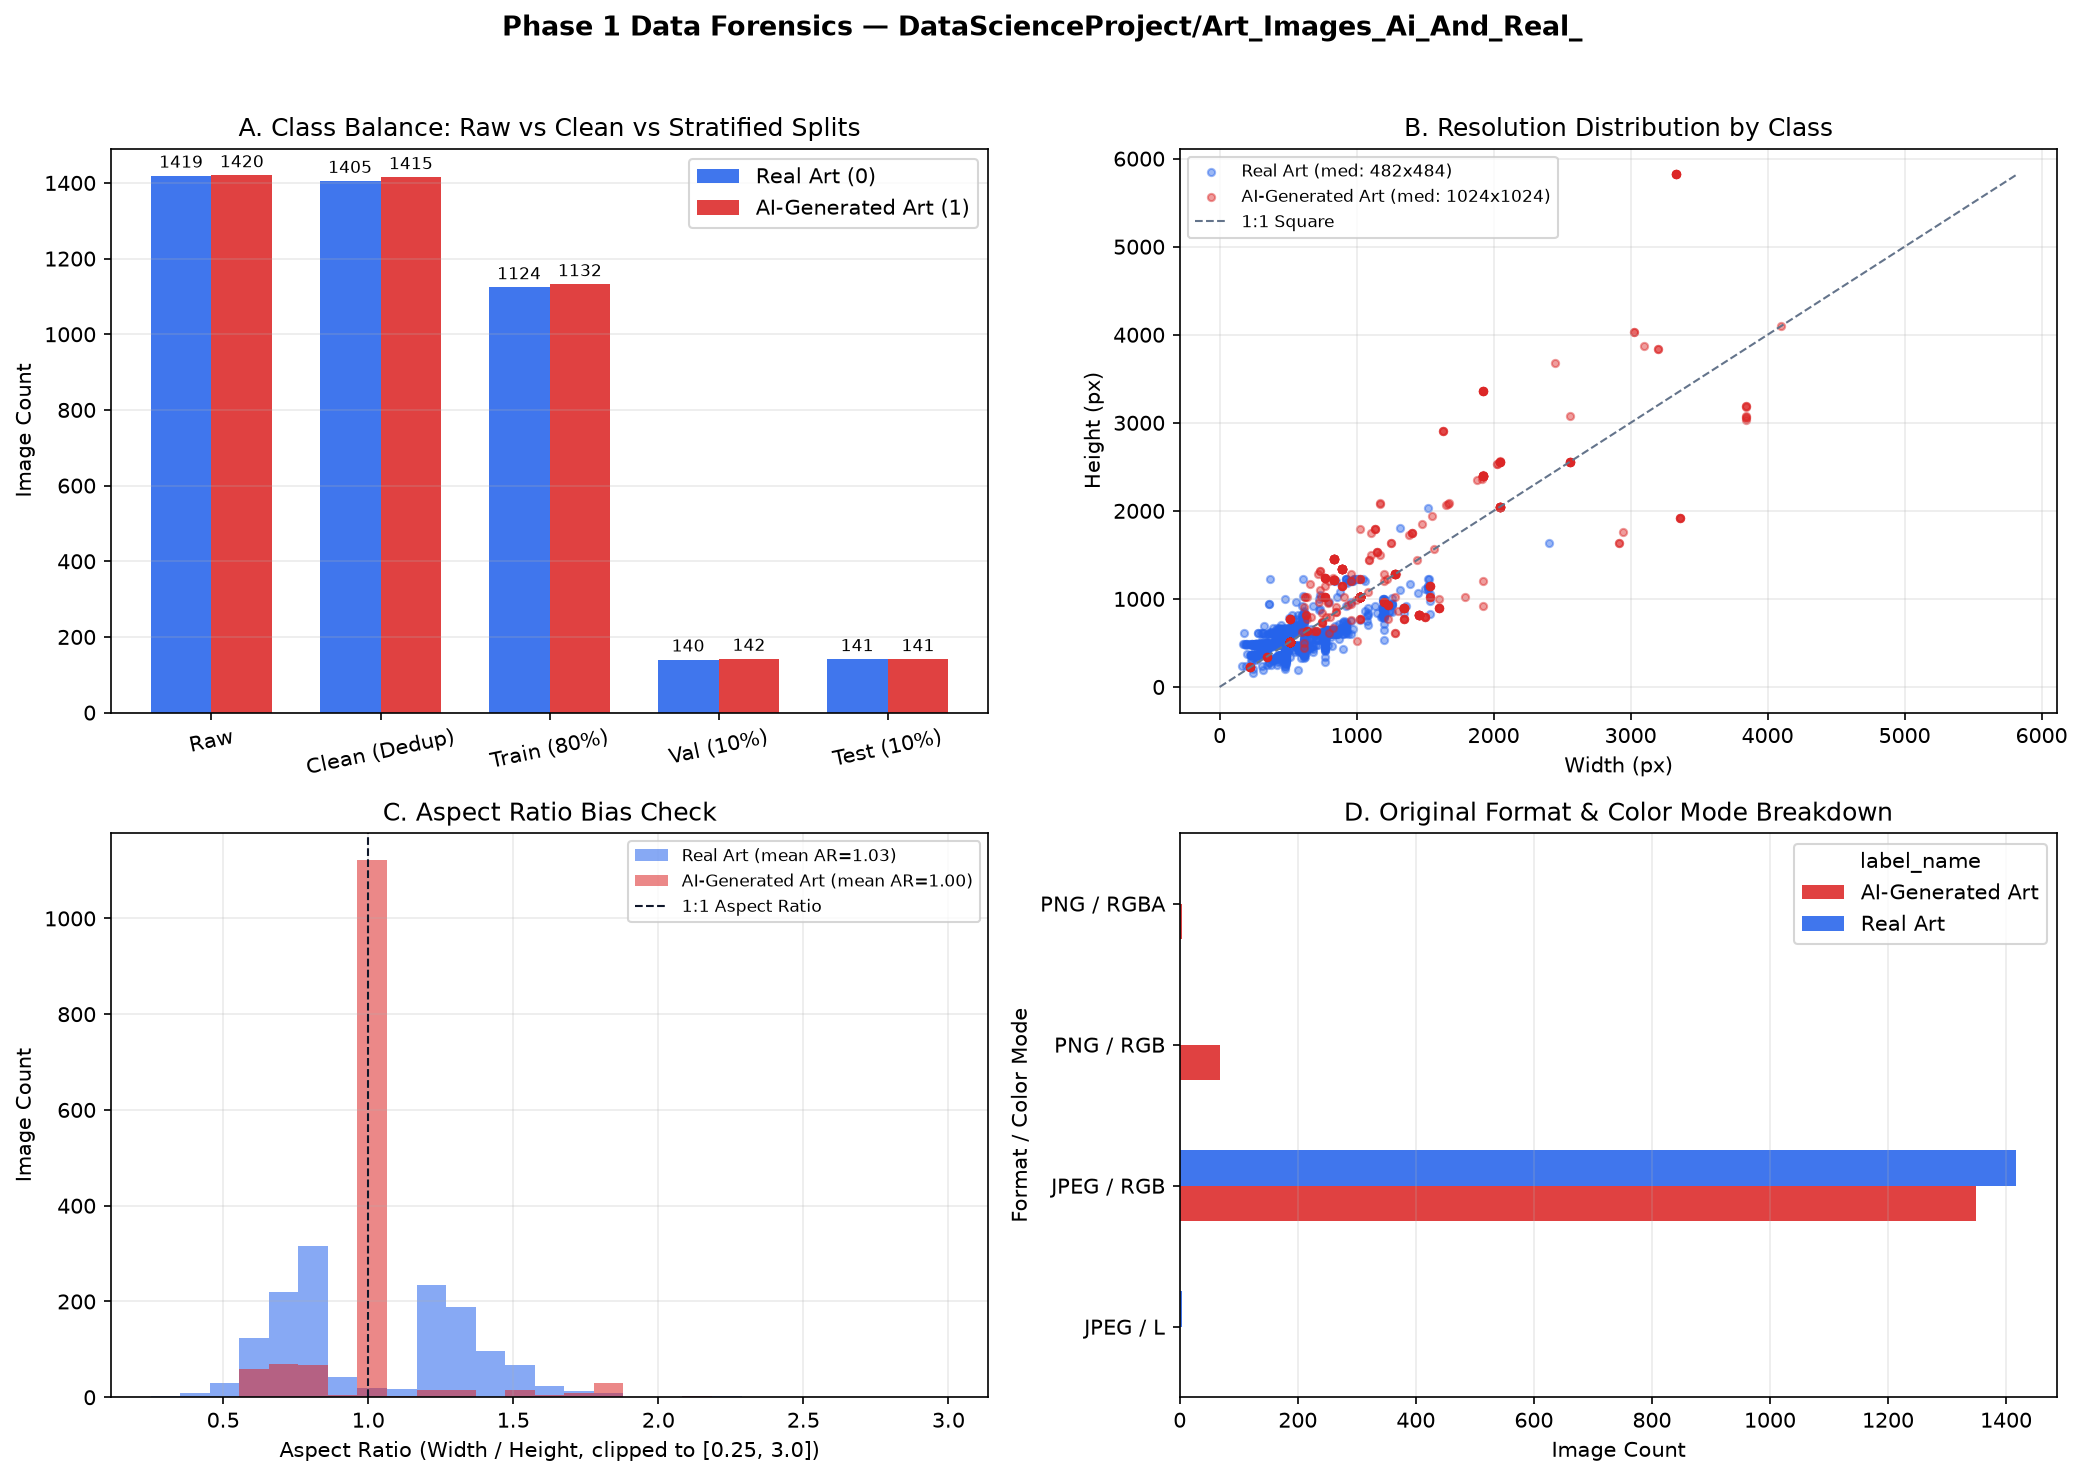

In [3]:
display(IPyImage(filename=str(FIGURES_DIR / 'phase1_data_forensics.png')))

## Visual Sanity Check (4×4 Grid setelah `center_crop=True` & Resize `224 × 224`)

Memverifikasi langsung bahwa konvensi label (`0 = Real Art`, `1 = AI-Generated Art`) sesuai secara visual dan *square center crop* tetap mempertahankan isi utama karya seni.

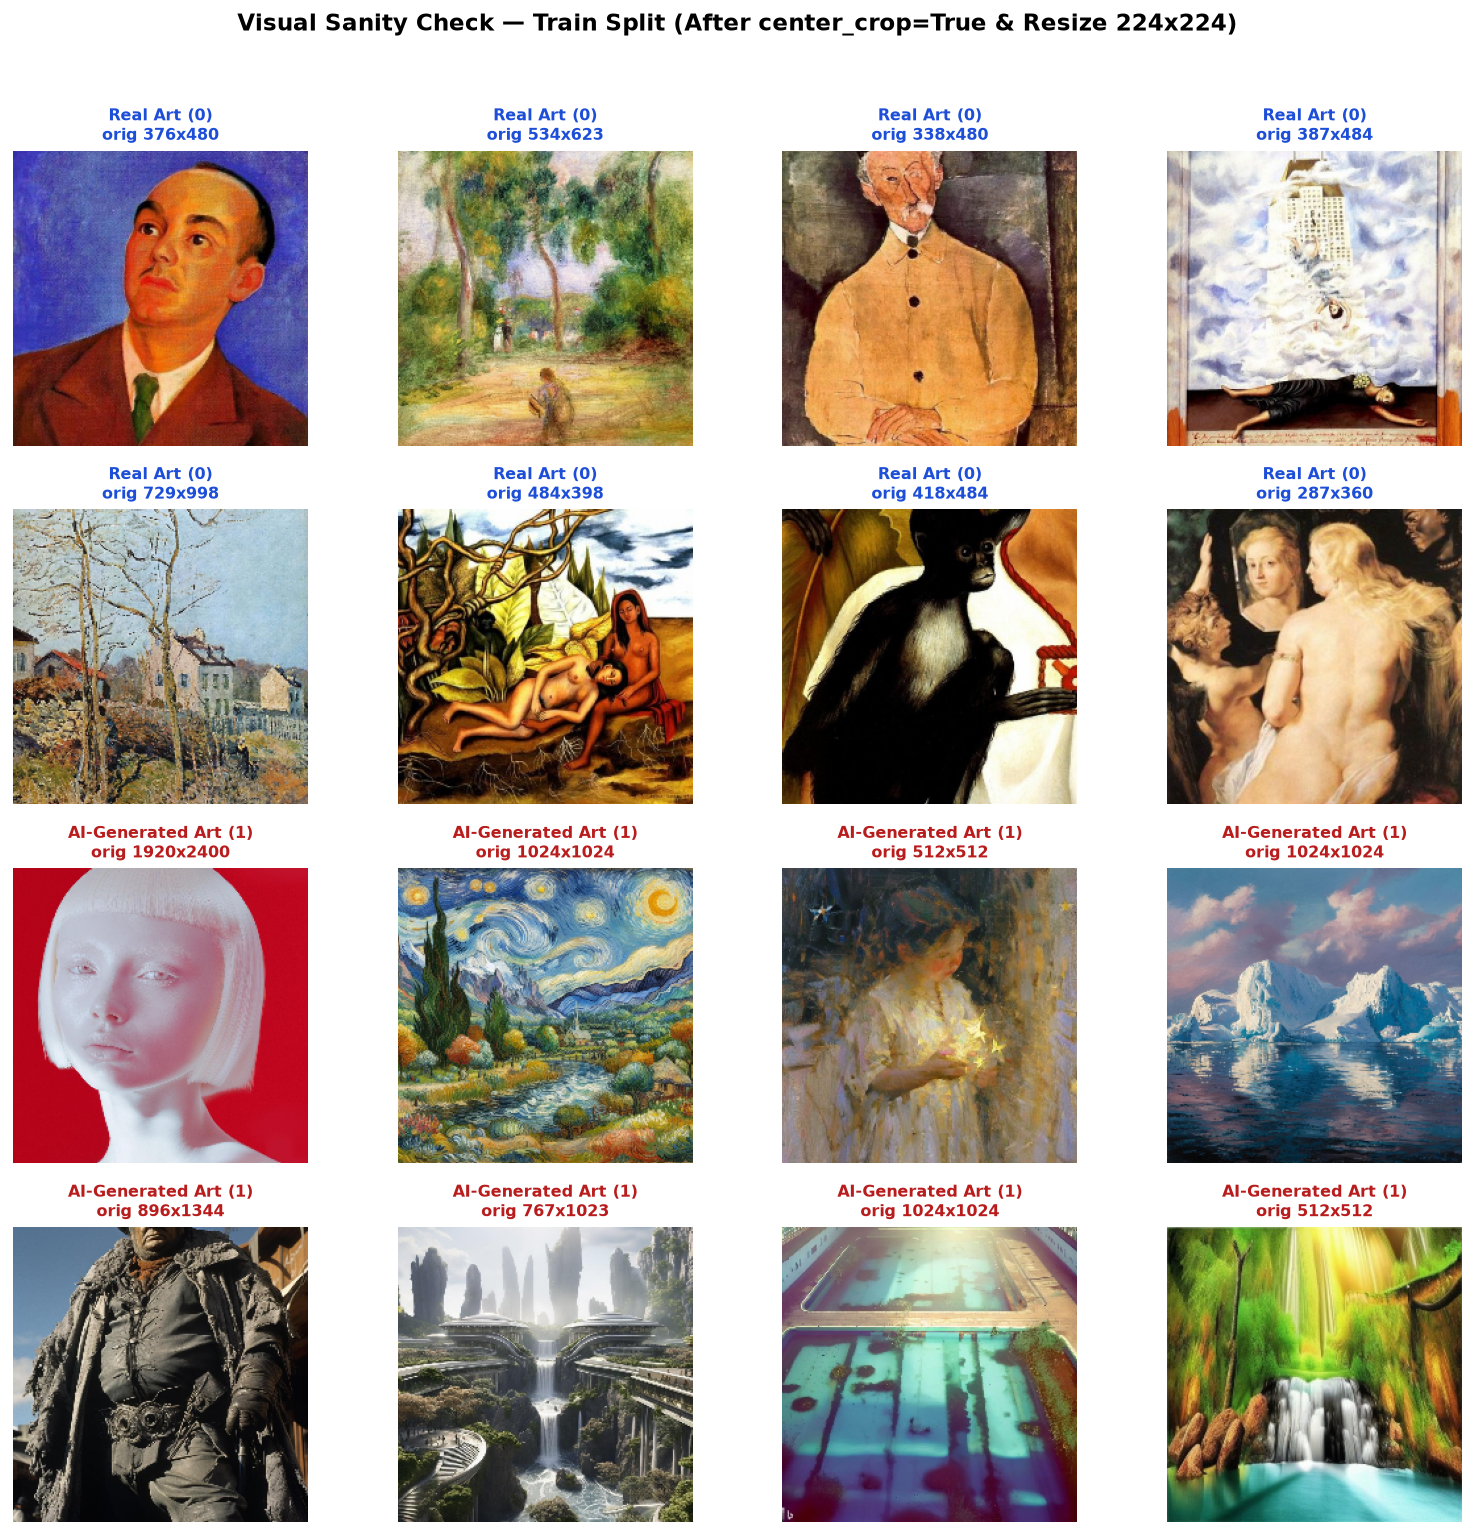

Saved: /Users/indra/Documents/mindrakusuma/deep-learning/reports/figures/phase1_visual_sanity_check.png


In [4]:
train_df = splits_df[splits_df['split'] == 'train']
real_samples = train_df[train_df['label'] == 0].sample(8, random_state=SEED)
ai_samples = train_df[train_df['label'] == 1].sample(8, random_state=SEED)
sanity_df = pd.concat([real_samples, ai_samples], ignore_index=True)

fig, axes = plt.subplots(4, 4, figsize=(12, 12), dpi=130)
for ax, (_, row) in zip(axes.flat, sanity_df.iterrows()):
    img_t, _ = _decode_and_resize(
        tf.constant(row['filepath']),
        tf.constant(row['label'], dtype=tf.float32),
        IMG_SIZE,
        center_crop=True,
    )
    ax.imshow(np.clip(img_t.numpy(), 0, 255).astype(np.uint8))
    color = '#1d4ed8' if row['label'] == 0 else '#b91c1c'
    ax.set_title(f"{row['label_name']} ({row['label']})\norig {row['width']}x{row['height']}", fontsize=9, color=color, fontweight='bold')
    ax.axis('off')

fig.suptitle('Visual Sanity Check — Train Split (After center_crop=True & Resize 224x224)', fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.96])
sanity_fig_path = FIGURES_DIR / 'phase1_visual_sanity_check.png'
fig.savefig(sanity_fig_path, bbox_inches='tight')
plt.show()
print('Saved:', sanity_fig_path)

## Conservative Augmentation Preview

Memastikan `RandomFlip`, `RandomRotation(0.05)`, dan `RandomZoom(0.1)` pada Train set tidak merusak struktur visual secara ekstrem.

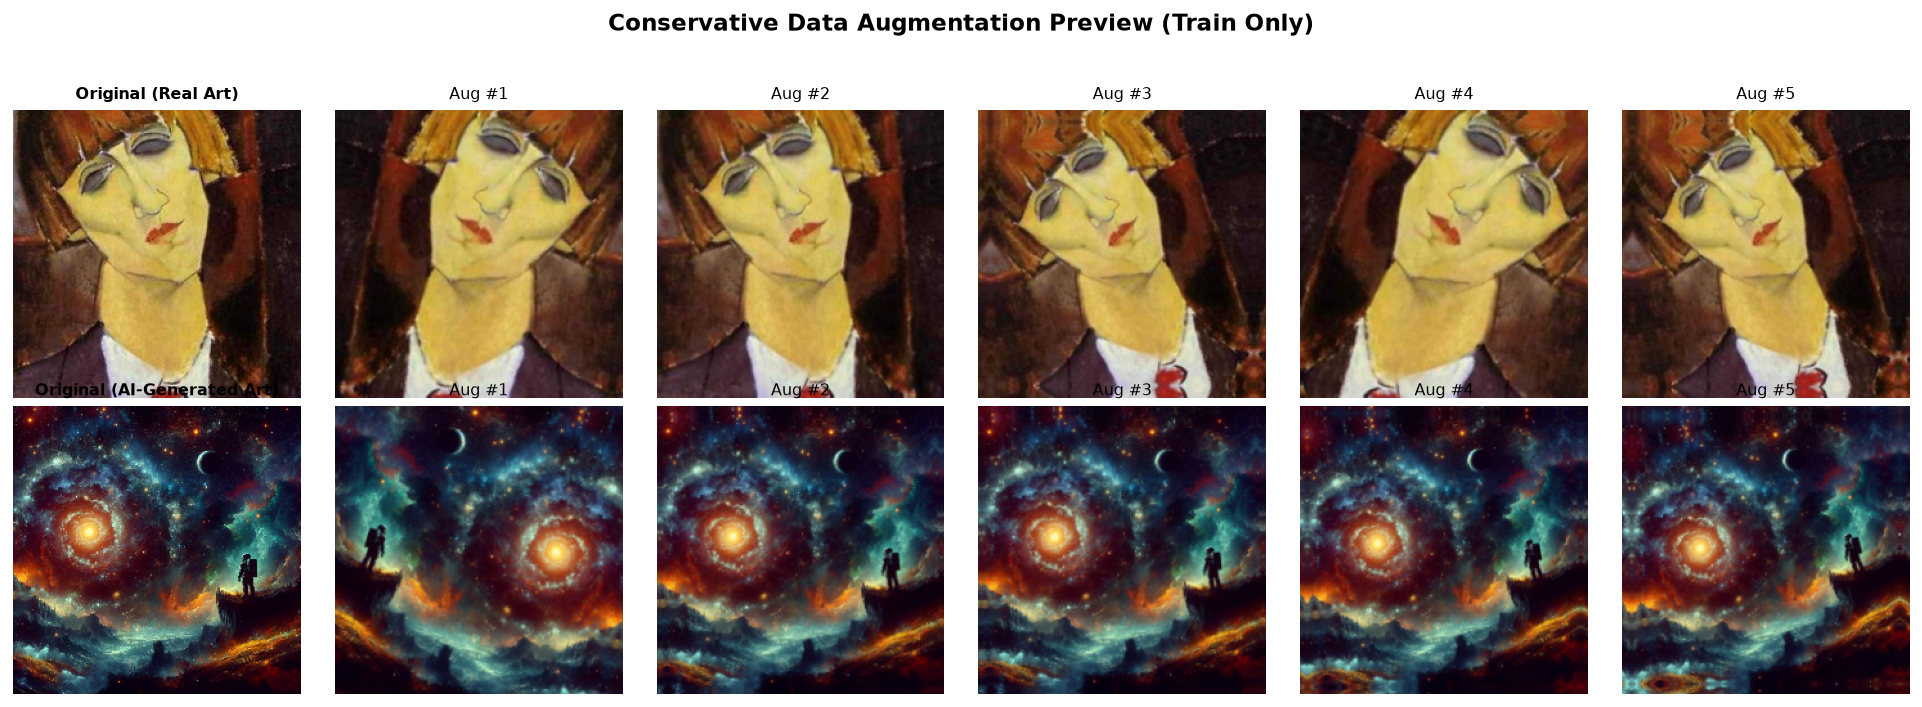

Saved: /Users/indra/Documents/mindrakusuma/deep-learning/reports/figures/phase1_augmentation_preview.png


In [5]:
aug_layer = build_augmentation_layer()
preview_rows = [
    train_df[train_df['label'] == 0].iloc[0],
    train_df[train_df['label'] == 1].iloc[0],
]

fig, axes = plt.subplots(2, 6, figsize=(15, 5.5), dpi=130)
for r_idx, row in enumerate(preview_rows):
    img_t, _ = _decode_and_resize(
        tf.constant(row['filepath']),
        tf.constant(row['label'], dtype=tf.float32),
        IMG_SIZE,
        center_crop=True,
    )
    axes[r_idx, 0].imshow(np.clip(img_t.numpy(), 0, 255).astype(np.uint8))
    axes[r_idx, 0].set_title(f"Original ({row['label_name']})", fontsize=9, fontweight='bold')
    axes[r_idx, 0].axis('off')
    batch_img = tf.expand_dims(img_t, 0)
    for c_idx in range(1, 6):
        aug_img = aug_layer(batch_img, training=True)[0].numpy()
        axes[r_idx, c_idx].imshow(np.clip(aug_img, 0, 255).astype(np.uint8))
        axes[r_idx, c_idx].set_title(f'Aug #{c_idx}', fontsize=9)
        axes[r_idx, c_idx].axis('off')

fig.suptitle('Conservative Data Augmentation Preview (Train Only)', fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.94])
aug_fig_path = FIGURES_DIR / 'phase1_augmentation_preview.png'
fig.savefig(aug_fig_path, bbox_inches='tight')
plt.show()
print('Saved:', aug_fig_path)